# Comparing structural features to confidence scores

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels.api as sm

In [2]:
entries = pd.read_csv('../data/interim/sequences_sample.csv')

In [3]:
entries['type'] = entries['label'].map(lambda label: 'binder' if label else 'decoy')

In [4]:
confidence_scores = pd.read_csv('../data/processed/af3_confidence_scores.csv')
structural_features = pd.read_csv('../data/processed/af3_structural_features.csv')

structure_scores = entries.merge(
    confidence_scores,
    how='left',
    left_on='index',
    right_on='structure_name',
).merge(
    structural_features,
    how='inner',
    left_on=['index', 'sample', 'seed'],
    right_on=['name', 'sample', 'seed'],
)

In [5]:
scanning_angle = scipy.stats.norm(loc=67.9, scale=np.sqrt(202.1))
structure_scores['scanning_angle_probability'] = structure_scores['scanning_angle'].apply(scanning_angle.pdf)

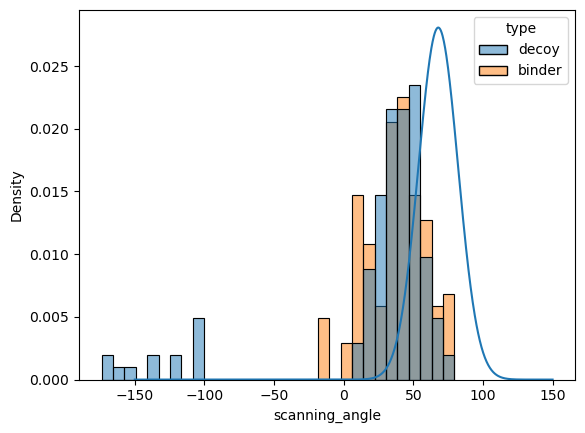

In [6]:
x = np.linspace(-150, 150, 1000)
plt.plot(x, scanning_angle.pdf(x))

sns.histplot(structure_scores, hue='type', x='scanning_angle', stat='density', common_norm=False)

plt.show()

In [7]:
pitch_angle = scipy.stats.gamma(a=1.20, loc=0.0365, scale=5.78)
structure_scores['pitch_angle_probability'] = structure_scores['pitch_angle'].apply(pitch_angle.pdf)

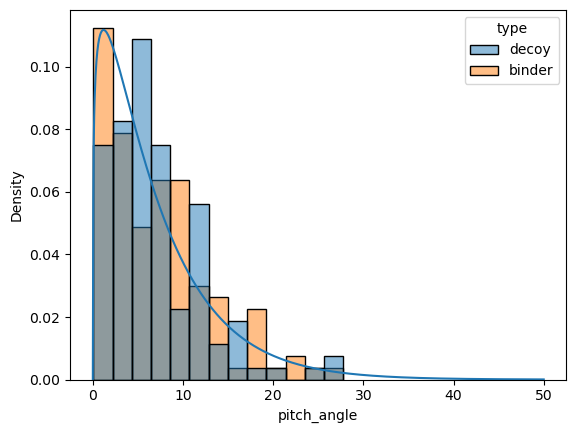

In [8]:
x = np.linspace(0, 50, 1000)
plt.plot(x, pitch_angle.pdf(x))

sns.histplot(structure_scores, x='pitch_angle', hue='type', stat='density', common_norm=False)

plt.show()

In [9]:
def z_score(x: float | np.ndarray) -> float | np.ndarray:
    means = [27.05, 28.62]
    variances = [0.468, 0.908]
    weights = [0.434, 0.566]

    pdfs = [
        w * scipy.stats.norm.pdf(x, loc=mu, scale=np.sqrt(var))
        for w, mu, var in zip(weights, means, variances, strict=True)
    ]

    return np.sum(pdfs, axis=0)


structure_scores['z_score_probability'] = structure_scores['z_score'].apply(z_score)

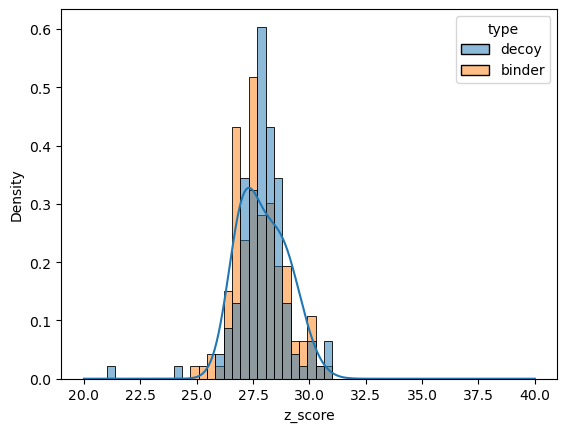

In [10]:
x = np.linspace(20, 40, 1000)
plt.plot(x, z_score(x))

sns.histplot(structure_scores, x='z_score', hue='type', stat='density', common_norm=False)

plt.show()

In [11]:
contact_probabilities = pd.read_csv('../data/external/tcr_pmhc_contacts.csv')

contact_probabilities['proportion'] = contact_probabilities.groupby('mhc_type')['proportion'].transform(
    lambda group: group / group.sum()
)

contact_maps = pd.read_csv('../data/processed/af3_contact_maps.csv')

contact_scores = (
    contact_maps.merge(
        contact_probabilities,
        how='left',
        on=[col for col in contact_probabilities if col != 'proportion'],
    )
    .groupby(['name', 'seed', 'sample'])['proportion']
    .aggregate(['sum', 'mean'])
)
contact_scores.columns = ['contact_map_probability_' + column_name for column_name in contact_scores.columns]

structure_scores = structure_scores.merge(
    contact_scores, how='left', left_on=['name', 'seed', 'sample'], right_index=True
)

<Axes: xlabel='score', ylabel='probability'>

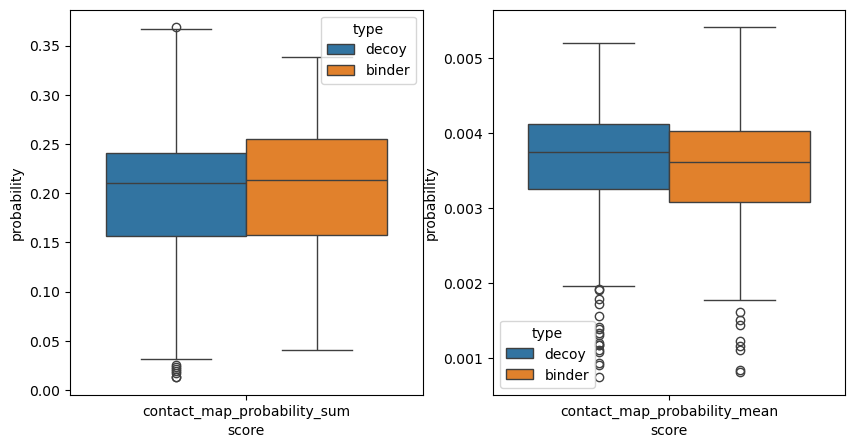

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_sum',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[0],
)

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_mean',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[1],
)

In [13]:
structure_scores['contact_map_probability'] = structure_scores['contact_map_probability_mean']

In [14]:
interactions = pd.read_csv('../data/processed/tcr_pmhc_interactions_temp.csv')

In [15]:
num_interactions = interactions.groupby('name').size()

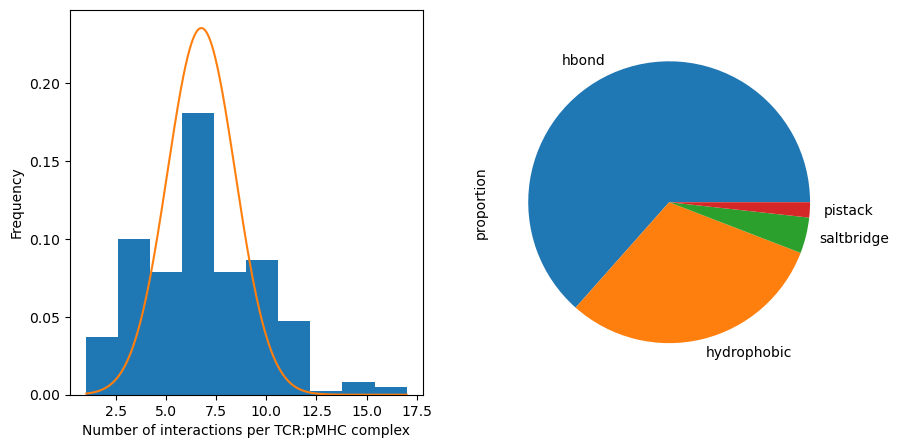

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

num_interactions.plot.hist(ax=axes[0], density=True)
x = np.linspace(num_interactions.min(), num_interactions.max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=np.sqrt(num_interactions.std()))

axes[0].plot(x, y, '-')

axes[0].set_xlabel('Number of interactions per TCR:pMHC complex')

interactions.value_counts('type', normalize=True).plot.pie(ax=axes[1])

plt.show()

In [17]:
interaction_types = interactions.value_counts(['type', 'name'])

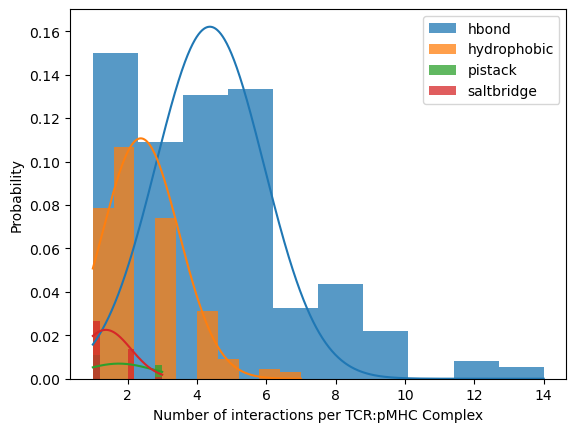

In [18]:
colours = plt.rcParams['axes.prop_cycle'].by_key()['color']

total_count = interaction_types.sum()

interaction_types_parameters = {}

for i, (interaction_type, group) in enumerate(interaction_types.reset_index().groupby('type')):
    interaction_types_parameters[interaction_type] = {}

    colour = colours[i % len(colours)]

    count = group['count']
    group_count = count.sum()

    mean = count.mean()
    std = count.std()
    weight = group_count / total_count

    interaction_types_parameters[interaction_type]['weight'] = weight
    interaction_types_parameters[interaction_type]['mean'] = mean
    interaction_types_parameters[interaction_type]['std'] = std

    x = np.linspace(count.min(), count.max(), 1000)
    y = scipy.stats.norm.pdf(x, loc=mean, scale=np.sqrt(std)) * weight

    plt.plot(x, y, '-', color=colour)

    counts, bins = np.histogram(count)
    probabilities = (counts / counts.sum()) * weight

    plt.stairs(
        probabilities,
        bins,
        fill=True,
        color=colour,
        alpha=0.75,
        label=interaction_type,
    )

plt.legend()
plt.ylabel('Probability')
plt.xlabel('Number of interactions per TCR:pMHC Complex')
plt.show()

In [19]:
af3_interactions = pd.read_csv('../data/processed/af3_interactions.csv')
af3_interactions = af3_interactions.merge(
    entries, how='left', left_on='name', right_on='index', suffixes=('_interaction', '')
)

ROC-AUC: 0.5866610301768991


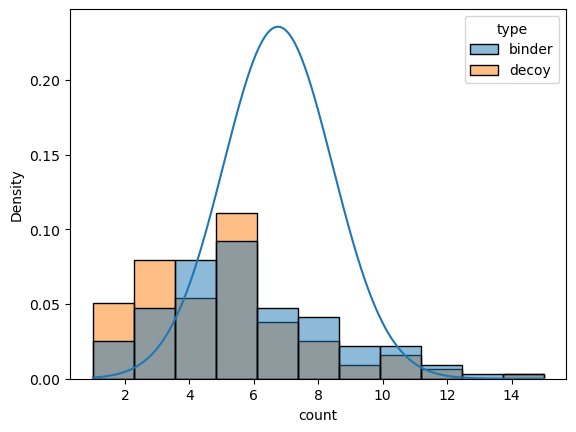

In [20]:
af3_interaction_counts = af3_interactions.groupby(['type', 'label', 'name', 'seed', 'sample']).size()
af3_interaction_counts.name = 'count'
af3_interaction_counts = af3_interaction_counts.reset_index()

sns.histplot(af3_interaction_counts, x='count', hue='type', stat='density')

x = np.linspace(af3_interaction_counts['count'].min(), af3_interaction_counts['count'].max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=np.sqrt(num_interactions.std()))
plt.plot(x, y, '-')

print('ROC-AUC:', sklearn.metrics.roc_auc_score(af3_interaction_counts['label'], af3_interaction_counts['count']))

plt.show()

In [21]:
af3_interaction_counts['num_interactions_probability'] = scipy.stats.norm.pdf(
    af3_interaction_counts['count'], loc=num_interactions.mean(), scale=np.sqrt(num_interactions.std())
)
structure_scores = structure_scores.merge(
    af3_interaction_counts[['name', 'seed', 'sample', 'num_interactions_probability']],
    how='left',
    left_on=['name', 'seed', 'sample'],
    right_on=['name', 'seed', 'sample'],
)
structure_scores['num_interactions_probability'] = structure_scores['num_interactions_probability'].fillna(0.0)

hbond ROC-AUC: 0.5367768595041322
hydrophobic ROC-AUC: 0.5488942307692308
pistack ROC-AUC: nan
saltbridge ROC-AUC: 0.3823529411764705


/home/imm/lina4096/.local/share/mamba/envs/tcr-pmhc-predicted-structures/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


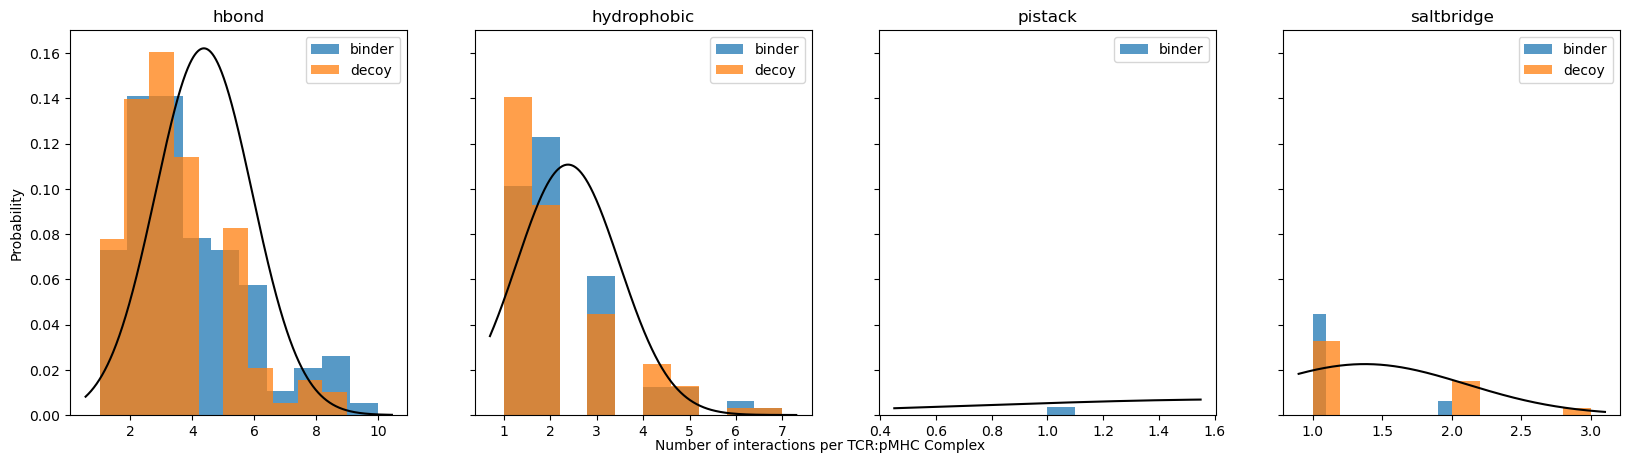

In [22]:
af3_interaction_types = af3_interactions.value_counts(
    ['name', 'seed', 'sample', 'type', 'label', 'type_interaction']
).reset_index()

total_count = af3_interaction_types['count'].sum()

number_of_interaction_types = len(interaction_types_parameters)

fig, axes = plt.subplots(1, number_of_interaction_types, figsize=(5 * number_of_interaction_types, 5), sharey=True)

for i, (interaction_type, group) in enumerate(af3_interaction_types.groupby('type_interaction')):
    group_count = group['count'].sum()

    weight = group_count / total_count

    for complex_type, sub_group in group.groupby('type'):
        counts, bins = np.histogram(sub_group['count'])
        probabilities = (counts / counts.sum()) * weight

        axes[i].stairs(
            probabilities,
            bins,
            fill=True,
            alpha=0.75,
            label=complex_type,
        )

    x = np.linspace(*axes[i].get_xlim(), 1000)
    y = (
        scipy.stats.norm.pdf(
            x,
            loc=interaction_types_parameters[interaction_type]['mean'],
            scale=np.sqrt(interaction_types_parameters[interaction_type]['std']),
        )
        * interaction_types_parameters[interaction_type]['weight']
    )

    axes[i].plot(x, y, '-', color='black')

    axes[i].set_title(interaction_type)
    axes[i].legend()

    print(interaction_type, 'ROC-AUC:', sklearn.metrics.roc_auc_score(group['label'], group['count']))

axes[0].set_ylabel('Probability')
fig.text(0.5, 0.04, 'Number of interactions per TCR:pMHC Complex', ha='center')

plt.show()

In [23]:
index = pd.MultiIndex.from_frame(structure_scores[['name', 'seed', 'sample']])
probabilities = pd.Series(np.zeros(len(index)), index=index)
probabilities.name = 'interaction_type_probability'
for interaction_type, params in interaction_types_parameters.items():
    interaction_type_counts = af3_interaction_types[
        af3_interaction_types['type_interaction'] == interaction_type
    ].set_index(['name', 'seed', 'sample'])['count']

    interaction_type_probabilities = interaction_type_counts.apply(
        lambda counts, params=params: params['weight']
        * scipy.stats.norm.pdf(counts, loc=params['mean'], scale=np.sqrt(params['std'])),
    )
    interaction_type_probabilities.name = 'interaction_type_probability'

    probabilities = probabilities.add(interaction_type_probabilities, fill_value=0.0)

structure_scores = structure_scores.merge(probabilities.reset_index(), how='left', on=['name', 'seed', 'sample'])

In [24]:
structure_probability_names = [
    'scanning_angle_probability',
    'pitch_angle_probability',
    'z_score_probability',
    'contact_map_probability',
    'num_interactions_probability',
    'interaction_type_probability',
]

In [25]:
with np.errstate(divide='ignore'):
    structure_scores['log_probability'] = structure_scores[structure_probability_names].apply(
        lambda row: np.sum(np.log(row)), axis=1
    )

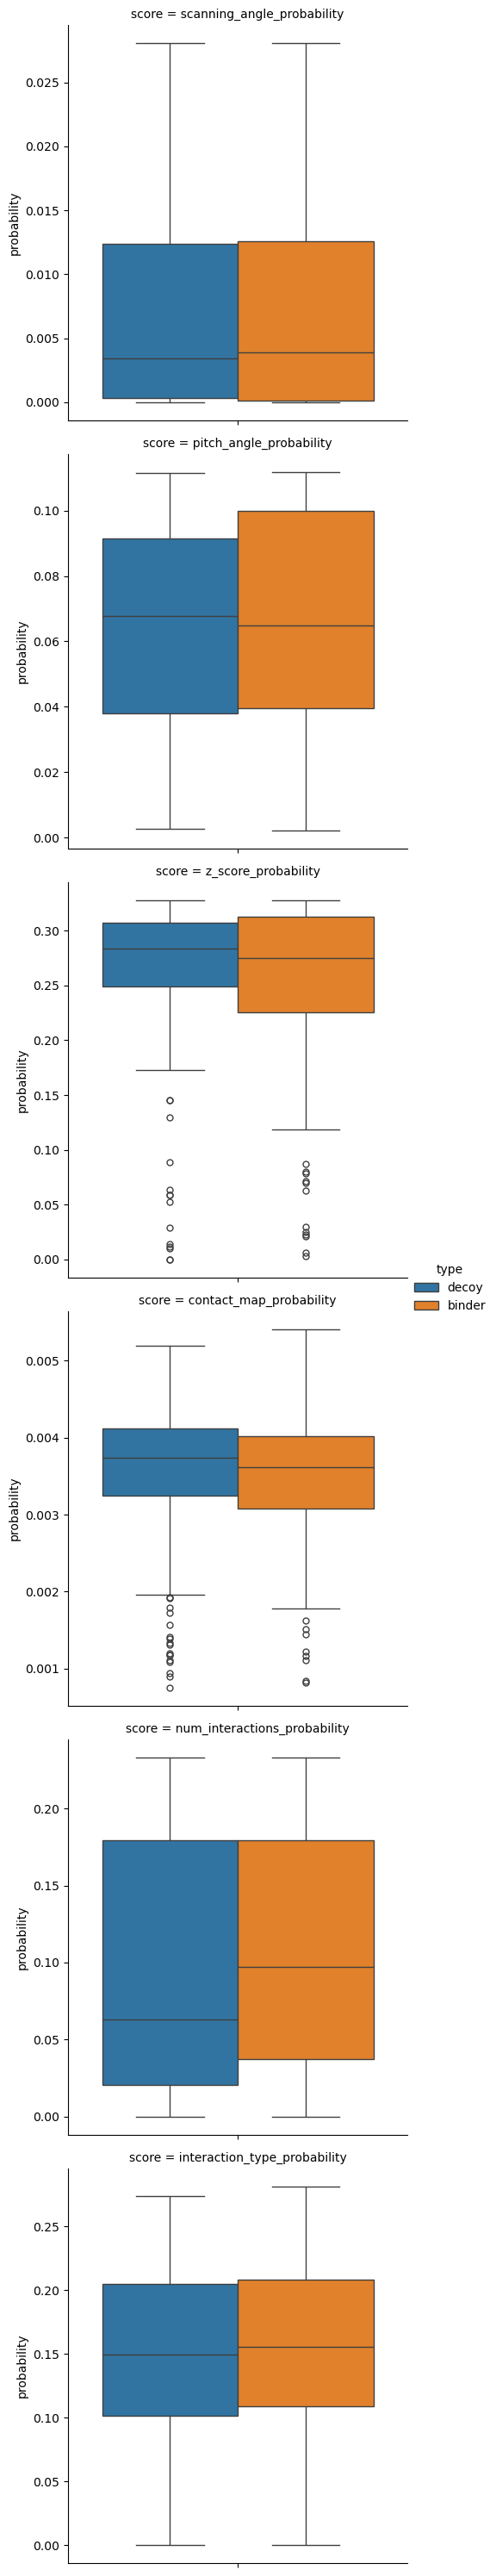

In [26]:
score_probabilities = structure_scores.melt(
    id_vars=['type', 'label'],
    value_vars=structure_probability_names,
    var_name='score',
    value_name='probability',
)
sns.catplot(score_probabilities, row='score', y='probability', hue='type', sharey=False, kind='box')

In [27]:
for score_name, group in score_probabilities.groupby('score'):
    print(score_name)
    print(sklearn.metrics.roc_auc_score(group['label'], group['probability']))

contact_map_probability
0.46060799999999996
interaction_type_probability
0.52208
num_interactions_probability
0.5407360000000001
pitch_angle_probability
0.49539200000000005
scanning_angle_probability
0.5110399999999999
z_score_probability
0.47622400000000004


In [28]:
confidence_columns = sorted(structure_scores.filter(regex='pae|ptm').columns.tolist())

In [29]:
best_r_squared = 0
best_reg = None
best_name = None

for confidence_column in confidence_columns:
    print(confidence_column)

    X = structure_scores[structure_probability_names]
    y = structure_scores[confidence_column]

    X = sm.add_constant(X)

    model = sm.OLS(y, X)
    reg = model.fit()

    if reg.rsquared > best_r_squared:
        best_r_squared = reg.rsquared
        best_reg = reg
        best_name = confidence_column

    print(reg.summary())
    print('\n\n')

print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')

print(best_reg.summary())

alpha_chain_alpha_chain_pae_min
                                   OLS Regression Results                                  
Dep. Variable:     alpha_chain_alpha_chain_pae_min   R-squared:                     -61.852
Model:                                         OLS   Adj. R-squared:                -63.404
Method:                              Least Squares   F-statistic:                    -39.86
Date:                             Mon, 30 Jun 2025   Prob (F-statistic):               1.00
Time:                                     17:36:04   Log-Likelihood:                 8311.9
No. Observations:                              250   AIC:                        -1.661e+04
Df Residuals:                                  243   BIC:                        -1.659e+04
Df Model:                                        6                                         
Covariance Type:                         nonrobust                                         
                                   coef    std e